# ANA-071: does RUN-184 recreate the measured TrpB landscape?

These figures use the immutable RUN-184 confirmation artifacts: 8,192 genotypes
disjoint from calibration, two actual assay replicates, and all four fresh
generator seeds (1001–1004). Fitness is shown in the native assay units stored
in the archive. No fit, parameter selection, observation-noise addition, missing
genotype imputation or favorable-seed selection is performed here.

**Primary comparison:** replicate-mean measured fitness against each noiseless
synthetic realization. Both observed replicates remain visible as sensitivity
context. Pooled replicate quantiles (the fitting convention) are also tabulated.
A fresh genotype panel within an already-studied assay is not new biological
replication. Four seeds are not confidence intervals.

In [1]:
from pathlib import Path
import importlib.util
import os
import sys
import tempfile

here = Path.cwd().resolve()
project = next(p for p in [here, *here.parents] if (p / 'AIM.md').exists())
analysis_dir = project / 'analyses/2026-11-24_ANA-071_run-184-trpb-architecture-calibration-and-landscape-adequacy'
notebook_dir = analysis_dir / 'notebooks'
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'adaptenv-ana071-matplotlib'))
sys.path.insert(0, str(notebook_dir))
from landscape_tools import run_landscape_analysis
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Image

context = run_landscape_analysis(project, analysis_dir)
fitness = context['fitness'].set_index('series')
metrics = context['metrics']
summary = context['summary']
seeds = context['seeds']
series = context['series']
figures = analysis_dir / 'figures'
figures.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 11, 'axes.labelsize': 10,
                     'legend.fontsize': 9, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
                     'pdf.fonttype': 42, 'ps.fonttype': 42, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.facecolor': 'white'})
seed_colors = dict(zip([f'seed_{s}' for s in seeds], ['#E69F00', '#D55E00', '#CC79A7', '#81582D']))
styles = {
    'measured_mean': dict(color='#111111', marker='D', label='Measured mean'),
    'measured_rep1': dict(color='#777777', marker='^', label='Measured replicate 1'),
    'measured_rep2': dict(color='#AAAAAA', marker='v', label='Measured replicate 2'),
    **{name: dict(color=color, marker='o', label=name.replace('seed_', 'Seed ')) for name, color in seed_colors.items()},
}
legend_handles = [Line2D([0], [0], color=style['color'], marker=style['marker'],
                        lw=1.1, ms=5, label=style['label']) for style in styles.values()]


def save_figure(fig, stem):
    fig.savefig(figures / f'{stem}.png', dpi=170, bbox_inches='tight')
    fig.savefig(figures / f'{stem}.pdf', bbox_inches='tight',
                metadata={'Title': stem, 'Author': 'ANA-071 reproducible notebook', 'CreationDate': None})
    plt.close(fig)
    display(Image(filename=str(figures / f'{stem}.png')))


print('Confirmation graph:', summary['graph'])
print('Native sigmoid bounds:', summary['sigmoid_bounds'])
print('Positive resolution:', context['epsilon'])
display(fitness.loc[:, ['mean', 'sd', 'q0.1', 'q0.5', 'q0.9', 'q0.99', 'q0.999',
                        'fraction_within_model_bounds']].round(6))

Matplotlib is building the font cache; this may take a moment.


Confirmation graph: {'nodes': 8192, 'edges': 15940, 'complete_faces': 566, 'fraction_of_q20_four_site_space': 0.0512, 'mean_observed_degree': 3.8916015625, 'possible_degree': 76, 'isolated_nodes': 136, 'isolated_node_fraction': 0.0166015625, 'face_denominator': 'All 566 observed complete two-site faces, including faces with unresolved effects; fully resolved conditional values are separately tabulated.', 'interpretation': 'Walk lengths and local peak fractions describe this sparse observed induced graph only, not whole-landscape searchability.'}
Native sigmoid bounds: {'lower': -0.0012343249149762148, 'upper': 0.0057529576803319075, 'span': 0.006987282595308122}
Positive resolution: 0.0008678124976651937


,mean,sd,q0.1,q0.5,q0.9,q0.99,q0.999,fraction_within_model_bounds
series,,,,,,,,
measured_mean,0.021257,0.058419,-0.011130,0.012574,0.043614,0.346183,0.583128,0.122803
measured_rep1,0.019614,0.059333,-0.014666,0.011044,0.044150,0.347057,0.579833,0.135254
measured_rep2,0.022899,0.058694,-0.011073,0.014305,0.046576,0.345442,0.589085,0.102783
seed_1001,0.001700,0.002185,-0.000873,0.001317,0.005070,0.005700,0.005746,1.000000
seed_1002,0.001699,0.002183,-0.000875,0.001303,0.005077,0.005703,0.005745,1.000000
seed_1003,0.001703,0.002183,-0.000875,0.001301,0.005087,0.005701,0.005746,1.000000
seed_1004,0.001704,0.002188,-0.000877,0.001305,0.005078,0.005701,0.005744,1.000000
measured_pooled_replicates,0.021257,0.059037,-0.012898,0.012683,0.045408,0.347048,0.588367,0.119019


## 1. Native fitness scale and upper tail

The fitted objective included the 10th, 50th and 90th fitness percentiles; it
did not fit the 99th and 99.9th percentiles. Their extension here tests the rare
high-fitness tail important to variant discovery. The upper tail remains high
in **both** measured replicates. A model's fixed sigmoid bounds apply to every
genotype, not just the sampled panel.

The ECDF's horizontal axis uses a symmetric-log scale only to make the narrow
synthetic distribution and broad empirical tails visible together. The other
panels retain native units. Averages, population SDs and all requested quantiles
are exported in `tables/landscape_fitness.csv`.

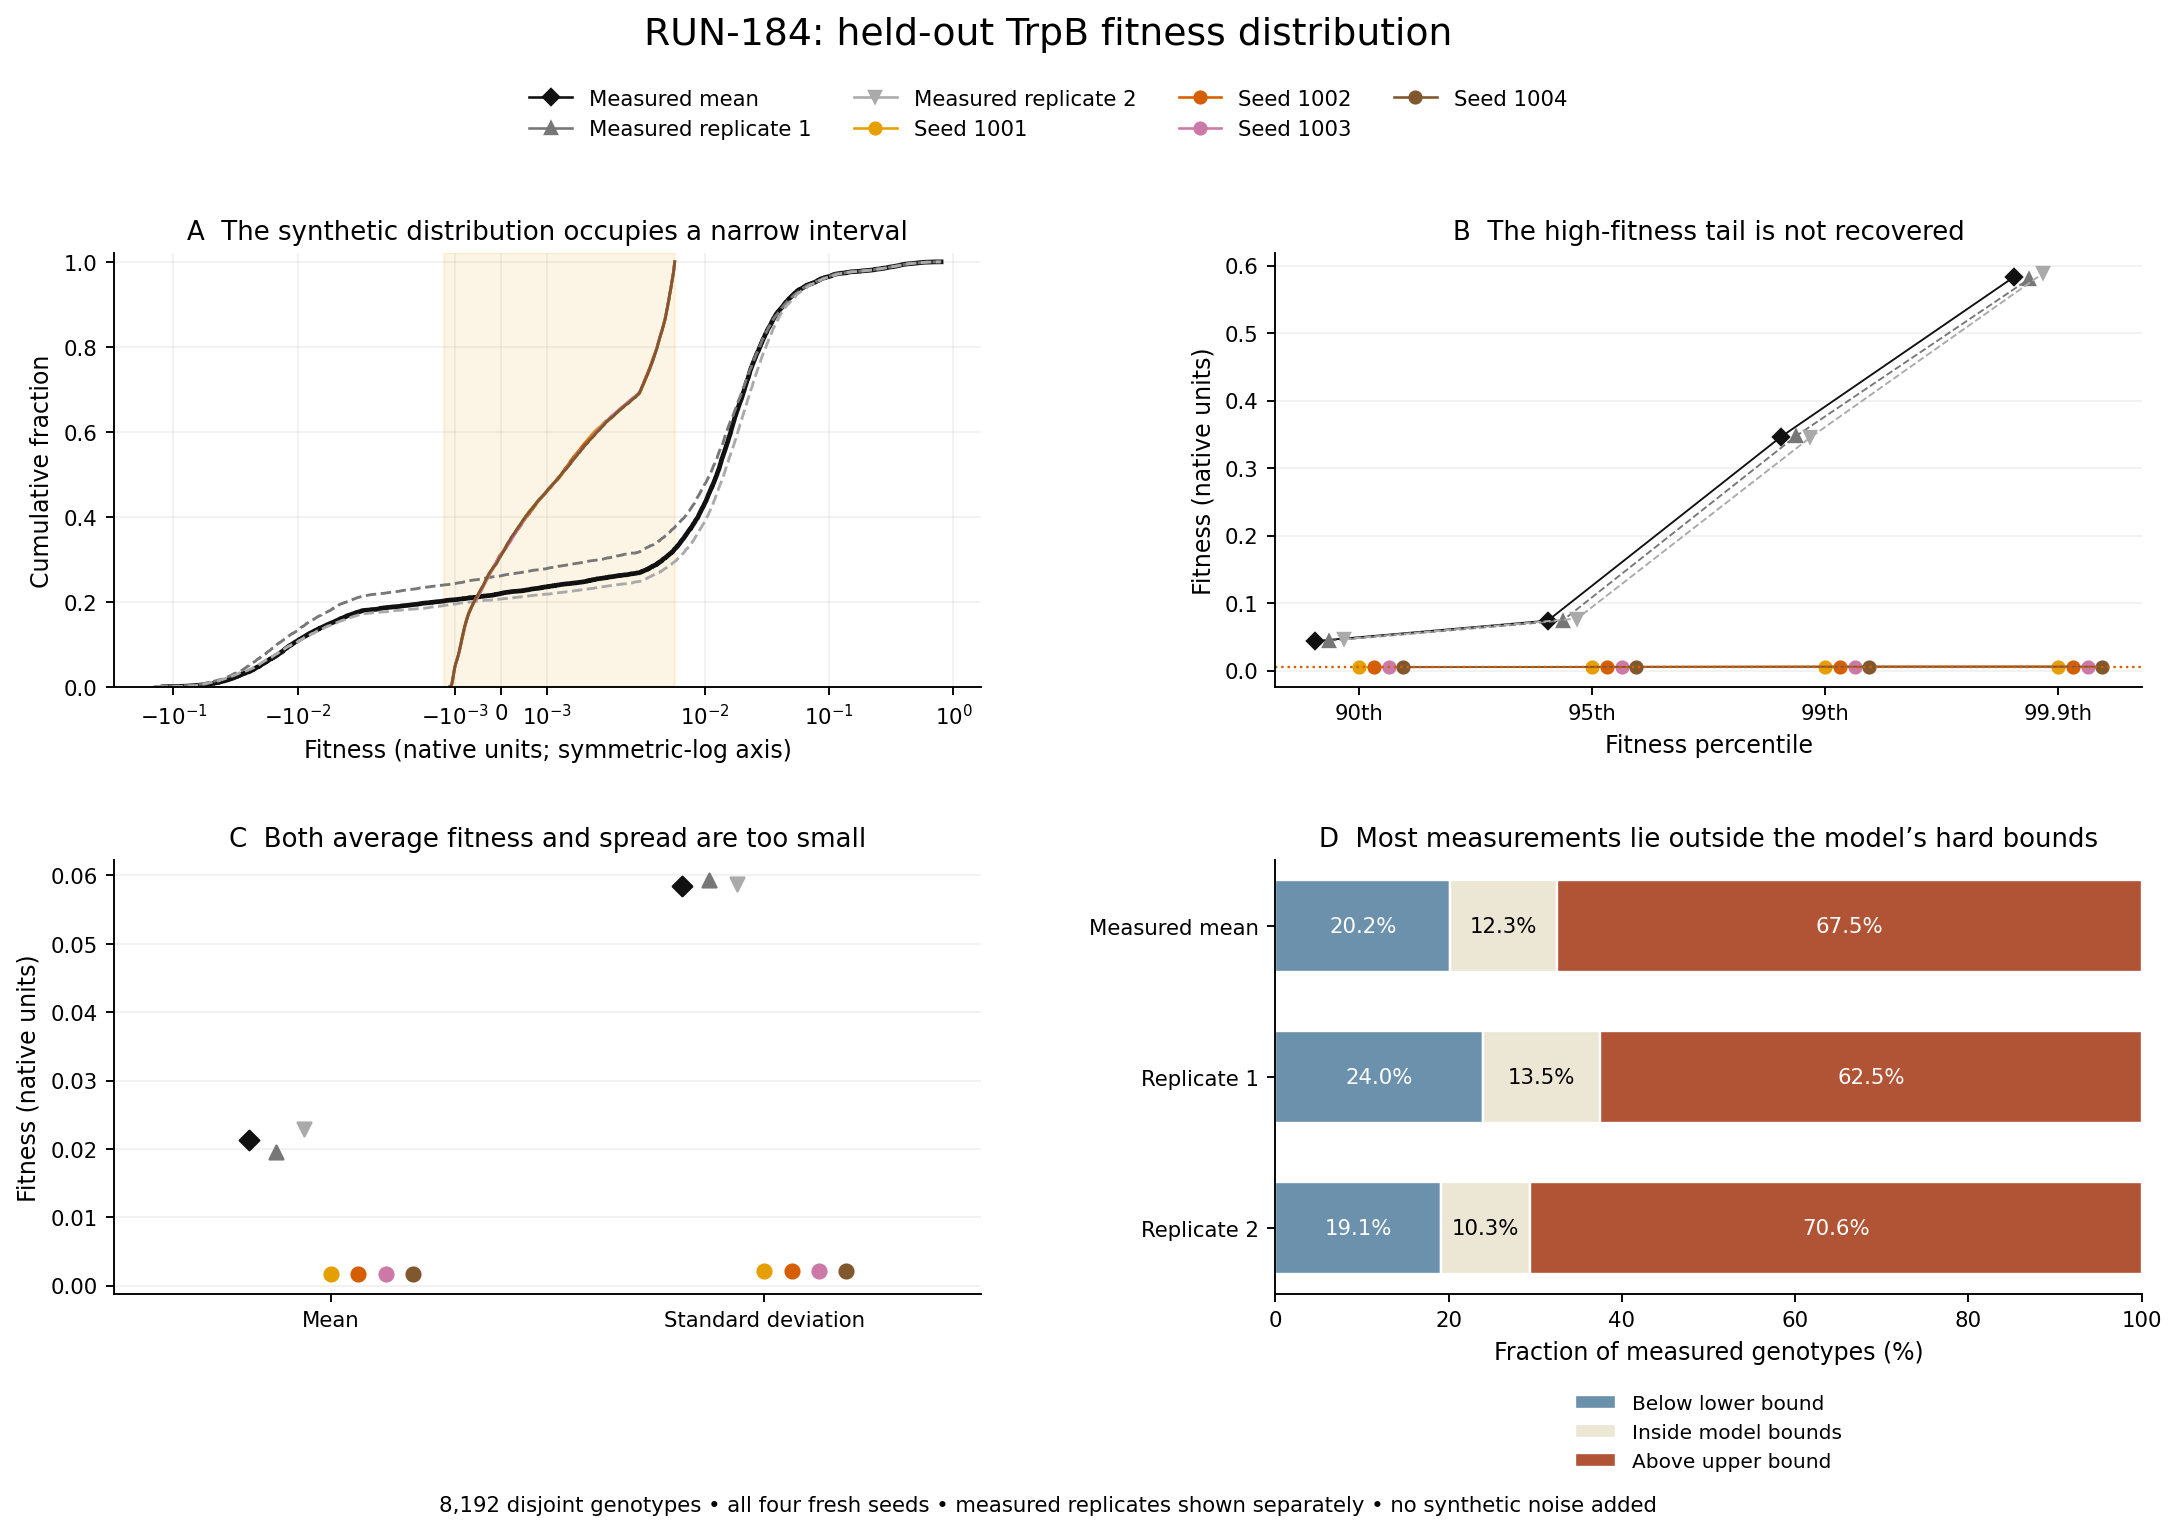

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(13.4, 9.0))
ax = axes[0, 0]
for name, values in series.items():
    sty = styles[name]
    values = np.sort(values)
    ax.plot(values, np.arange(1, len(values) + 1) / len(values), color=sty['color'],
            lw=2.0 if name == 'measured_mean' else 1.2,
            ls='--' if name.startswith('measured_rep') else '-')
ax.axvspan(summary['sigmoid_bounds']['lower'], summary['sigmoid_bounds']['upper'],
           color='#E69F00', alpha=.10)
ax.set_xscale('symlog', linthresh=.003, linscale=1)
ax.set(xlabel='Fitness (native units; symmetric-log axis)', ylabel='Cumulative fraction',
       title='A  The synthetic distribution occupies a narrow interval', ylim=(0, 1.02))
ax.grid(alpha=.17)

ax = axes[0, 1]
qvalues, qlabels = [.9, .95, .99, .999], ['90th', '95th', '99th', '99.9th']
offsets = dict(zip(series, np.linspace(-.19, .19, len(series))))
for name in series:
    sty = styles[name]
    ax.plot(np.arange(4) + offsets[name], [fitness.loc[name, f'q{q:g}'] for q in qvalues],
            color=sty['color'], marker=sty['marker'], lw=.8, ms=5,
            ls='--' if name.startswith('measured_rep') else '-')
ax.axhline(summary['sigmoid_bounds']['upper'], color='#D55E00', ls=':', lw=1)
ax.set(xticks=np.arange(4), xticklabels=qlabels, xlabel='Fitness percentile',
       ylabel='Fitness (native units)', title='B  The high-fitness tail is not recovered')
ax.grid(axis='y', alpha=.17)

ax = axes[1, 0]
for name in series:
    sty = styles[name]
    ax.scatter(np.arange(2) + offsets[name], [fitness.loc[name, m] for m in ['mean', 'sd']],
               color=sty['color'], marker=sty['marker'], s=34, zorder=3)
ax.set(xticks=[0, 1], xticklabels=['Mean', 'Standard deviation'], xlim=(-.5, 1.5),
       ylabel='Fitness (native units)', title='C  Both average fitness and spread are too small')
ax.grid(axis='y', alpha=.17)

ax = axes[1, 1]
names = ['measured_mean', 'measured_rep1', 'measured_rep2']
coverage = fitness.loc[names, ['fraction_below_model_lower_bound',
                              'fraction_within_model_bounds', 'fraction_above_model_upper_bound']]
left = np.zeros(len(names))
for column, color, label in zip(coverage.columns, ['#6B91AD', '#ECE6D5', '#B15335'],
                               ['Below lower bound', 'Inside model bounds', 'Above upper bound']):
    values = coverage[column].to_numpy()
    ax.barh(np.arange(len(names)), values * 100, left=left * 100, color=color, label=label,
            height=.61, edgecolor='white')
    for i, value in enumerate(values):
        if value > .065:
            ax.text((left[i] + value / 2) * 100, i, f'{value:.1%}', ha='center', va='center',
                    color='black' if column == 'fraction_within_model_bounds' else 'white', fontsize=9)
    left += values
ax.set(yticks=np.arange(len(names)), yticklabels=['Measured mean', 'Replicate 1', 'Replicate 2'],
       xlabel='Fraction of measured genotypes (%)', xlim=(0, 100),
       title='D  Most measurements lie outside the model’s hard bounds')
ax.invert_yaxis()
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.19), ncol=1, frameon=False, fontsize=8.5)
fig.suptitle('RUN-184: held-out TrpB fitness distribution', fontsize=16, y=.995)
fig.legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(.5, .96), ncol=4, frameon=False)
fig.text(.5, .018, '8,192 disjoint genotypes • all four fresh seeds • measured replicates shown separately • no synthetic noise added',
         ha='center', fontsize=9)
fig.subplots_adjust(left=.09, right=.98, top=.84, bottom=.16, hspace=.40, wspace=.34)
save_figure(fig, '01_fitness_distribution')

## 2. Unfitted landscape metrics on the same observed graph

The 8,192 measured genotypes cover only 5.12% of the 20⁴ space. We use the same
15,940 single-substitution edges and 566 complete two-site faces for every map.
The mean observed degree is about 3.89, versus 76 possible neighbors per node.
Missing neighbors are not assigned values. Panel-local peaks and walk lengths
**do not estimate whole-library searchability**.

The first resolution is the original run's strict zero threshold. The second is
an explicitly exploratory sensitivity: epsilon = 0.001 × the **calibration**
replicate-mean fitness range. A face is sign epistatic when at least one mutation
reverses sign across its two backgrounds, with both changes exceeding epsilon;
reciprocal sign epistasis requires both mutations to reverse. Denominators remain
all 566 faces, including unresolved faces. Fully resolved conditional statistics
are retained in the table, so thresholding cannot silently alter the denominator.

Uniform-uphill walk length is an exact dynamic-programming expectation: start
uniformly among the observed nodes, choose uniformly among neighbors whose
increase exceeds epsilon, and stop when none remain. Isolated nodes count as
panel-local peaks; their count and nonisolated peak fractions are tabulated.

Mutation effects use the same observed edges, oriented from lower to higher
alphabet index. Absolute effect distributions are orientation independent.
The pooled slope regresses mutant-minus-background fitness on background fitness.
This shared subtraction produces mathematical coupling; **a negative slope alone
is not evidence for biological diminishing returns**. The additional per-mutation
slopes hold site and allele pair fixed, requiring at least ten observed backgrounds.
They are descriptive, subject to the same caveat, and not extra acceptance tests.

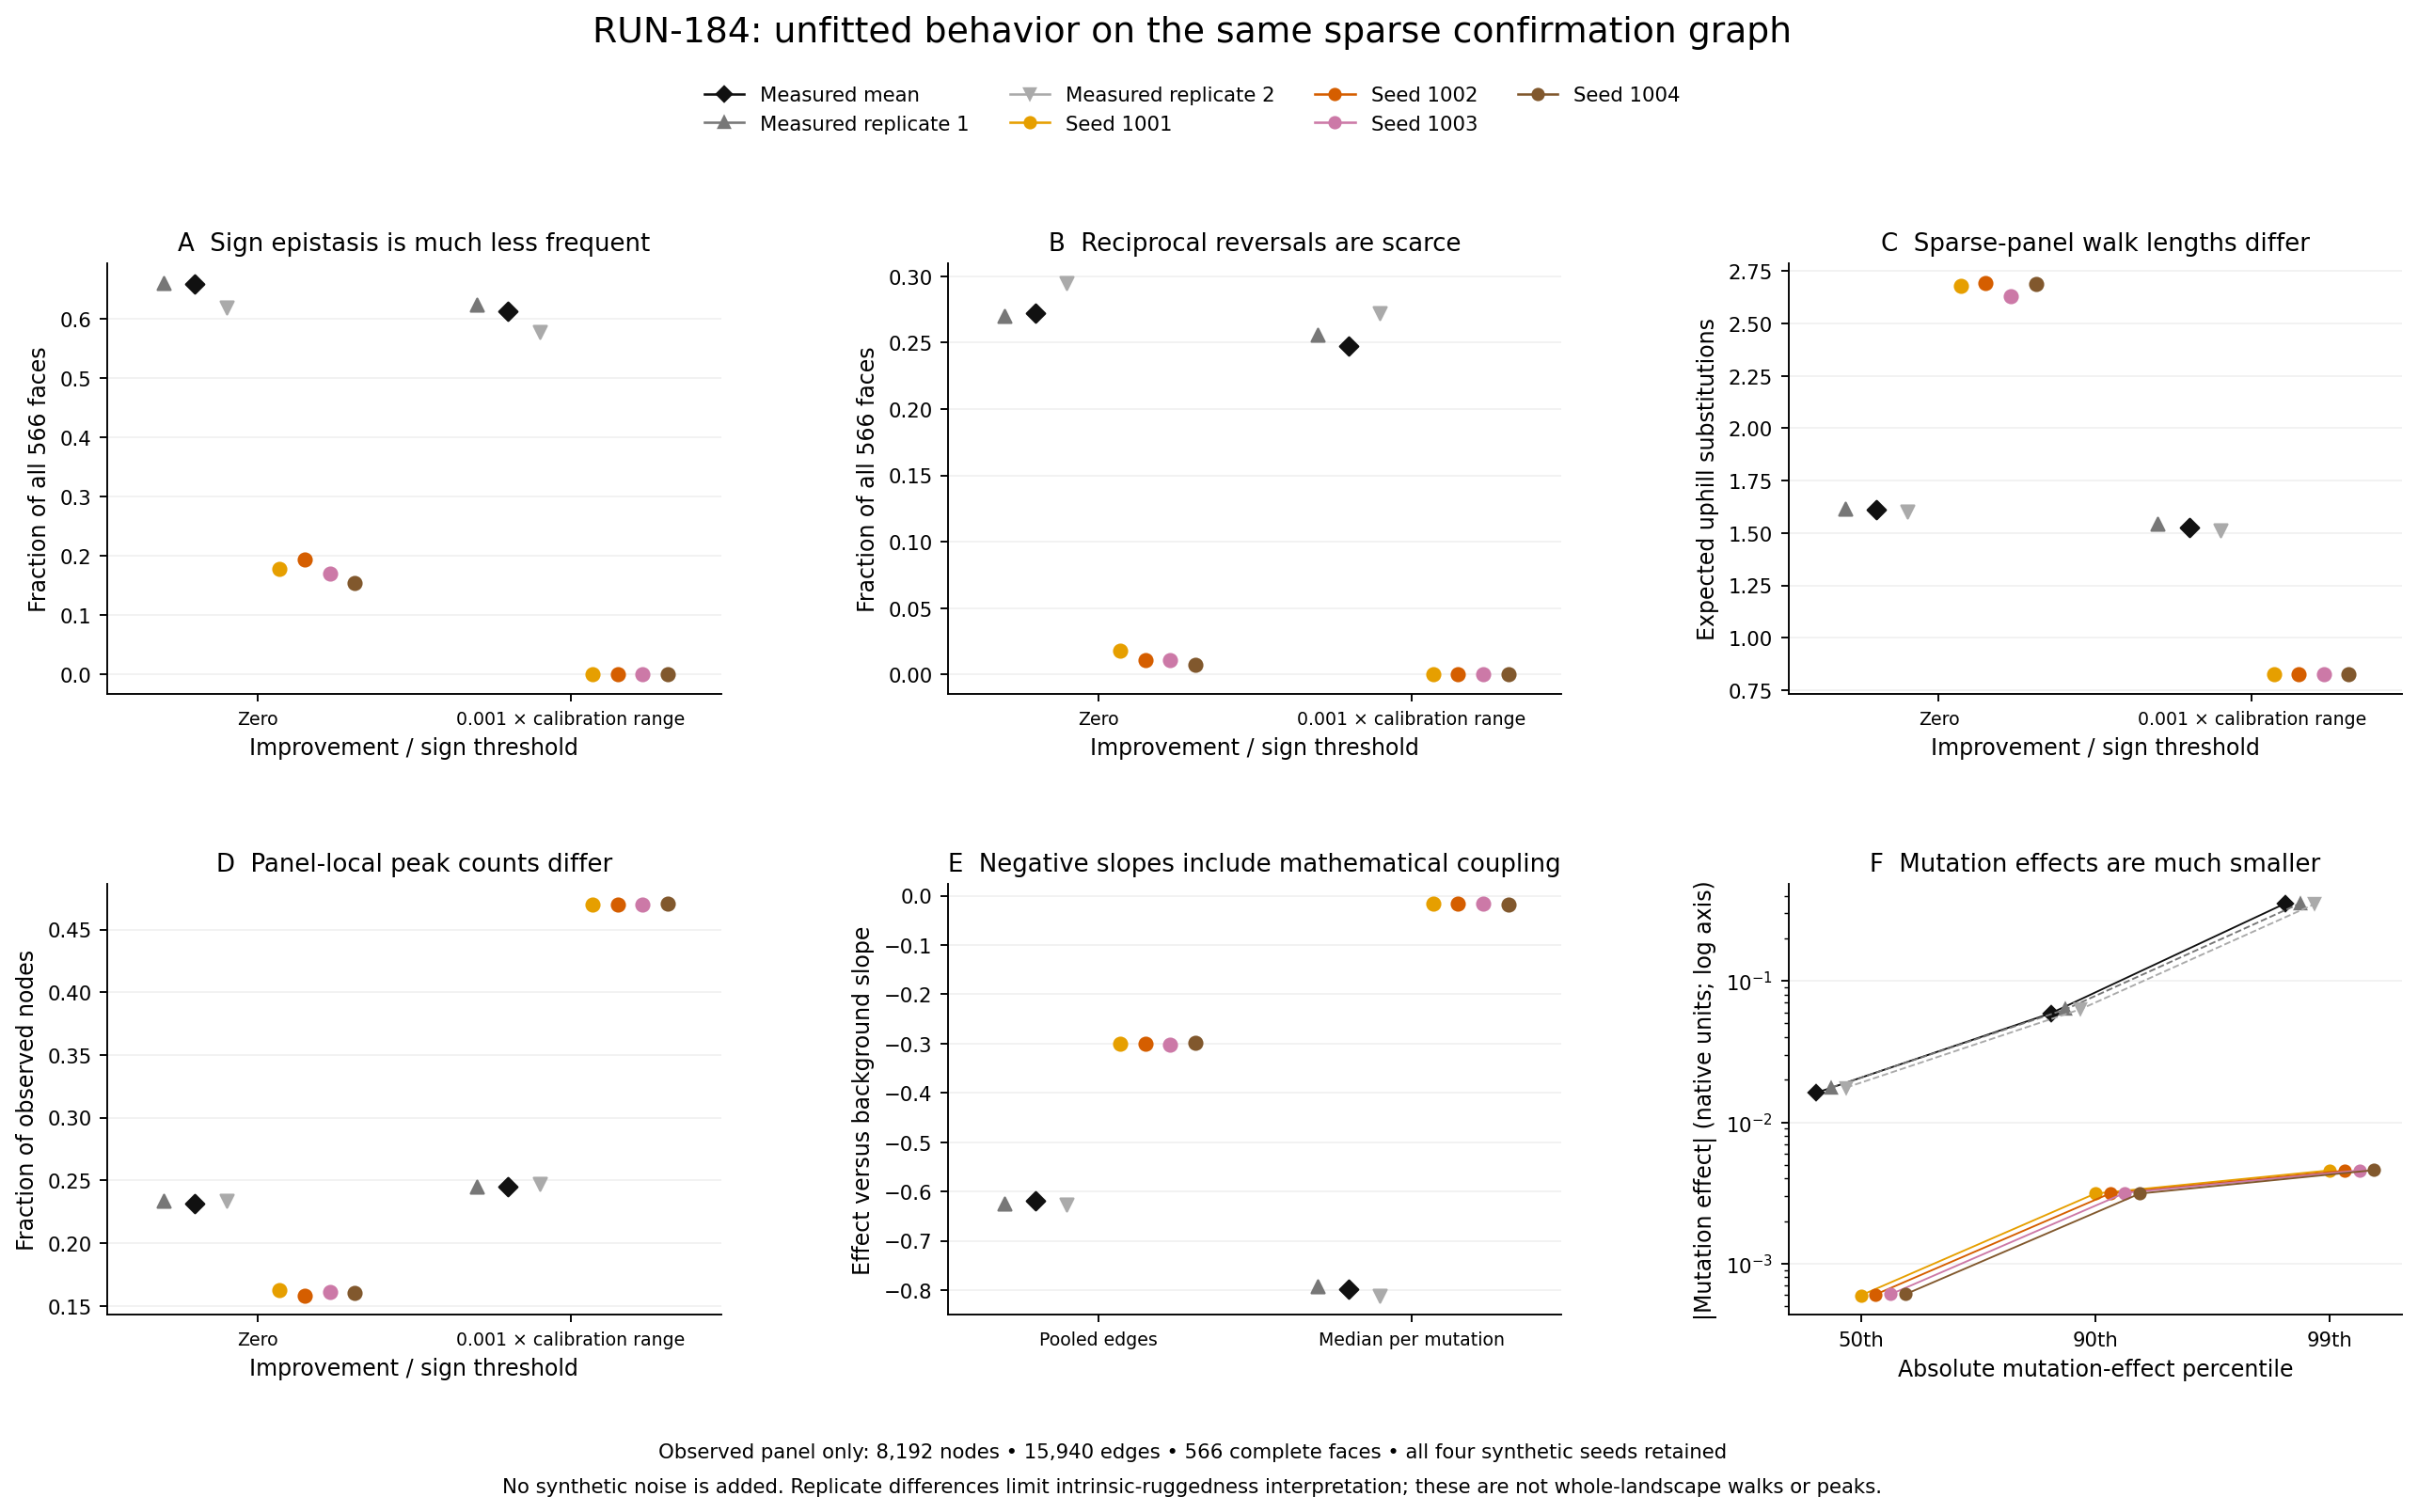

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15.6, 9.4))
positions = {'measured_mean': -.20, 'measured_rep1': -.30, 'measured_rep2': -.10,
             **dict(zip(seed_colors, [.07, .15, .23, .31]))}
thresholds = ['zero', 'calibration_range_0.001']


def graph_panel(ax, metric, title, ylabel):
    for i, threshold in enumerate(thresholds):
        rows = metrics.loc[metrics.threshold == threshold].set_index('series')
        for name in series:
            sty = styles[name]
            ax.scatter(i + positions[name], rows.loc[name, metric], color=sty['color'],
                       marker=sty['marker'], s=34, zorder=3)
    ax.set(xticks=[0, 1], xticklabels=['Zero', '0.001 × calibration range'],
           xlabel='Improvement / sign threshold', ylabel=ylabel, title=title, xlim=(-.48, 1.48))
    ax.tick_params(axis='x', labelsize=8)
    ax.grid(axis='y', alpha=.17)


graph_panel(axes[0, 0], 'sign_epistasis_fraction', 'A  Sign epistasis is much less frequent', 'Fraction of all 566 faces')
graph_panel(axes[0, 1], 'reciprocal_sign_epistasis_fraction', 'B  Reciprocal reversals are scarce', 'Fraction of all 566 faces')
graph_panel(axes[0, 2], 'uniform_uphill_steps', 'C  Sparse-panel walk lengths differ', 'Expected uphill substitutions')
graph_panel(axes[1, 0], 'panel_local_peak_fraction', 'D  Panel-local peak counts differ', 'Fraction of observed nodes')

ax = axes[1, 1]
zero = metrics.loc[metrics.threshold == 'zero'].set_index('series')
for name in series:
    sty = styles[name]
    mutation_median = summary['mutation_slopes'][name]['median']
    ax.scatter(np.arange(2) + positions[name],
               [zero.loc[name, 'fixed_orientation_diminishing_returns_slope'], mutation_median],
               color=sty['color'], marker=sty['marker'], s=34, zorder=3)
ax.set(xticks=[0, 1], xticklabels=['Pooled edges', 'Median per mutation'],
       ylabel='Effect versus background slope', title='E  Negative slopes include mathematical coupling', xlim=(-.48, 1.48))
ax.tick_params(axis='x', labelsize=8)
ax.grid(axis='y', alpha=.17)

ax = axes[1, 2]
dfe = context['dfe'].set_index('series')
for name in series:
    sty = styles[name]
    ax.plot(np.arange(3) + offsets[name], [dfe.loc[name, f'absolute_q{q:g}'] for q in [.5, .9, .99]],
            color=sty['color'], marker=sty['marker'], lw=.8, ms=5,
            ls='--' if name.startswith('measured_rep') else '-')
ax.set_yscale('log')
ax.set(xticks=np.arange(3), xticklabels=['50th', '90th', '99th'], xlabel='Absolute mutation-effect percentile',
       ylabel='|Mutation effect| (native units; log axis)', title='F  Mutation effects are much smaller')
ax.grid(axis='y', alpha=.17)
fig.suptitle('RUN-184: unfitted behavior on the same sparse confirmation graph', fontsize=16, y=.995)
fig.legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(.5, .96), ncol=4, frameon=False)
fig.text(.5, .035, 'Observed panel only: 8,192 nodes • 15,940 edges • 566 complete faces • all four synthetic seeds retained',
         ha='center', fontsize=9)
fig.text(.5, .012, 'No synthetic noise is added. Replicate differences limit intrinsic-ruggedness interpretation; these are not whole-landscape walks or peaks.',
         ha='center', fontsize=9)
fig.subplots_adjust(left=.065, right=.985, top=.83, bottom=.13, hspace=.44, wspace=.37)
save_figure(fig, '02_unfitted_landscape')

## Numerical findings and verification

`landscape_summary.json` retains the complete native-scale results, replicate
sensitivity, model hard bounds, graph geometry and explicit interpretation
limits. The replicate comparison is a sensitivity check, not a claim that two
noisy observations reveal an exact biological fitness map.

The graph is reconstructed independently of the frozen model diagnostics.
Forty checks reproduce all archived graph counts and five zero-threshold
statistics for the measured mean and four synthetic seeds to 1e-12. No expensive
auxiliary inference is repeated. The notebook is deterministic from the four
SHA-256-identified frozen source artifacts; all output CSV/JSON files regenerate.

In [4]:
display(context['comparison'].round(6))
display(pd.Series(summary['replicate_sensitivity']))
import json
print(json.loads((analysis_dir / 'tables/landscape_verification.json').read_text())['maximum_absolute_error'])

,metric,threshold,measured_mean,measured_rep1,measured_rep2,synthetic_min,synthetic_median,synthetic_max,synthetic_median_minus_measured,measured_inside_four_seed_range
0,sign_epistasis_fraction,zero,0.659011,0.660777,0.618375,0.153710,0.174028,0.194346,-0.484982,False
1,sign_epistasis_fraction,calibration_range_0.001,0.613074,0.623675,0.577739,0.000000,0.000000,0.000000,-0.613074,False
2,reciprocal_sign_epistasis_fraction,zero,0.272085,0.270318,0.295053,0.007067,0.010601,0.017668,-0.261484,False
3,reciprocal_sign_epistasis_fraction,calibration_range_0.001,0.247350,0.256184,0.272085,0.000000,0.000000,0.000000,-0.247350,False
4,fixed_orientation_diminishing_returns_slope,zero,-0.619054,-0.624083,-0.626515,-0.301642,-0.299589,-0.299159,0.319465,False
5,fixed_orientation_diminishing_returns_slope,calibration_range_0.001,-0.619054,-0.624083,-0.626515,-0.301642,-0.299589,-0.299159,0.319465,False
6,uniform_uphill_steps,zero,1.610711,1.617404,1.602455,2.628779,2.685547,2.694068,1.074836,False
7,uniform_uphill_steps,calibration_range_0.001,1.524669,1.543969,1.512906,0.824863,0.825733,0.826267,-0.698936,False
8,panel_local_peak_fraction,zero,0.231567,0.233887,0.233887,0.158325,0.160706,0.162476,-0.070862,False
9,panel_local_peak_fraction,calibration_range_0.001,0.244995,0.244995,0.246948,0.469849,0.469910,0.470825,0.224915,False


replicate_pearson_r                                                                                            0.959895
replicate_rmse                                                                                                 0.017045
replicate2_minus_replicate1_mean                                                                               0.003285
edge_effect_pearson_r                                                                                          0.942191
edge_effect_rmse                                                                                               0.022866
edge_effect_sign_disagreement_zero                                                                             0.231556
cross_replicate_pooled_slope_background1_effect2                                                              -0.583851
cross_replicate_pooled_slope_background2_effect1                                                              -0.600826
interpretation                          

4.440892098500626e-16
